# Part 1 — Enhancement comparison: spatial (Unit II) vs frequency domain (Unit III)
**Questions answered here**
1. Which noise type do X-rays have, and which denoiser suits it? (Unit IV)
2. How do CLAHE / HE / histogram specification compare with homomorphic and high-pass filtering?
3. Which method makes the lungs easiest to separate from the background? (matters for Part 3)

Run `python scripts/run_eda.py` first (creates `splits.csv`).

In [13]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                         # run from repo root (safe to re-run)
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.io_utils import ROOT, load_config, load_gray, load_mask
from src.preprocessing import preprocess
from src.enhancement import enhance, METHODS, homomorphic_H, quality_report
from src.noise_models import estimate_sigma
from src.evaluation.plots import before_after_grid, spectra_grid, zoom_crops
from src.evaluation.compare import (compare_enhancements, denoise_benchmark, load_pre, sample_rows)
cfg = load_config()
df = pd.read_csv(ROOT / cfg["paths"]["features"] / "splits.csv")
train = df[df.split == "train"]
FIG = ROOT / cfg["paths"]["reports"] / "figures"; FIG.mkdir(parents=True, exist_ok=True)
train.class_name.value_counts()

class_name
Normal             7134
Lung_Opacity       4205
Viral Pneumonia     944
Name: count, dtype: int64

## 1. Noise handling (Unit IV)
Estimated noise level of the real images, then a benchmark of denoisers on *simulated* noise of each type (PSNR/SSIM vs the clean image).

In [14]:
sig = [estimate_sigma(load_pre(r, cfg)) for r in sample_rows(train, 20).itertuples()]
print(f"Estimated noise sigma on real images: mean={np.mean(sig):.2f}, max={np.max(sig):.2f}")
bench = denoise_benchmark(train, cfg, n=15)
bench.to_csv(ROOT / cfg["paths"]["reports"] / "denoise_benchmark.csv", index=False)
bench.pivot(index="denoiser", columns="noise", values="psnr").round(2)

Estimated noise sigma on real images: mean=0.63, max=1.05


denoise benchmark: 100%|██████████| 15/15 [00:10<00:00,  1.39it/s]


noise,gaussian(s=15),poisson,salt&pepper(3%),speckle(0.15)
denoiser,,,,
bilateral,33.63,28.07,21.11,31.09
gaussian5,32.97,29.68,29.89,31.55
median3,31.66,26.75,41.70,29.22
median5,32.94,29.34,37.10,31.37
nlm,30.12,19.87,20.30,22.76
none,24.93,19.79,20.09,22.30


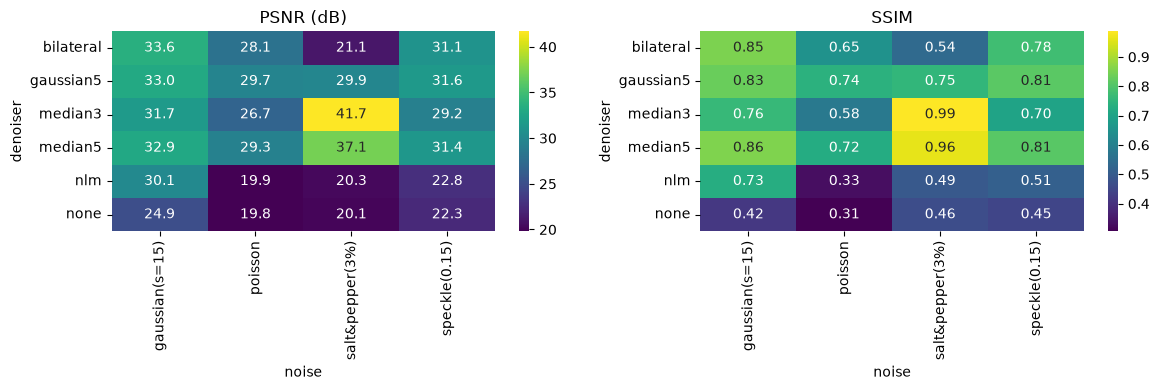

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(bench.pivot(index="denoiser", columns="noise", values="psnr"), annot=True, fmt=".1f", ax=ax[0], cmap="viridis"); ax[0].set_title("PSNR (dB)")
sns.heatmap(bench.pivot(index="denoiser", columns="noise", values="ssim"), annot=True, fmt=".2f", ax=ax[1], cmap="viridis"); ax[1].set_title("SSIM")
plt.tight_layout(); plt.savefig(FIG / "denoise_benchmark.png", dpi=150)

**Expected pattern:** median wins on salt-and-pepper; Gaussian/NLM/bilateral win on Gaussian and Poisson noise; blurring everything (Gaussian5) costs edge detail. Record your actual finding and the denoiser you chose in `config.yaml` here:

> *Finding:* ...

## 2. Visual comparison
One image per class, all enhancement methods, with histograms.

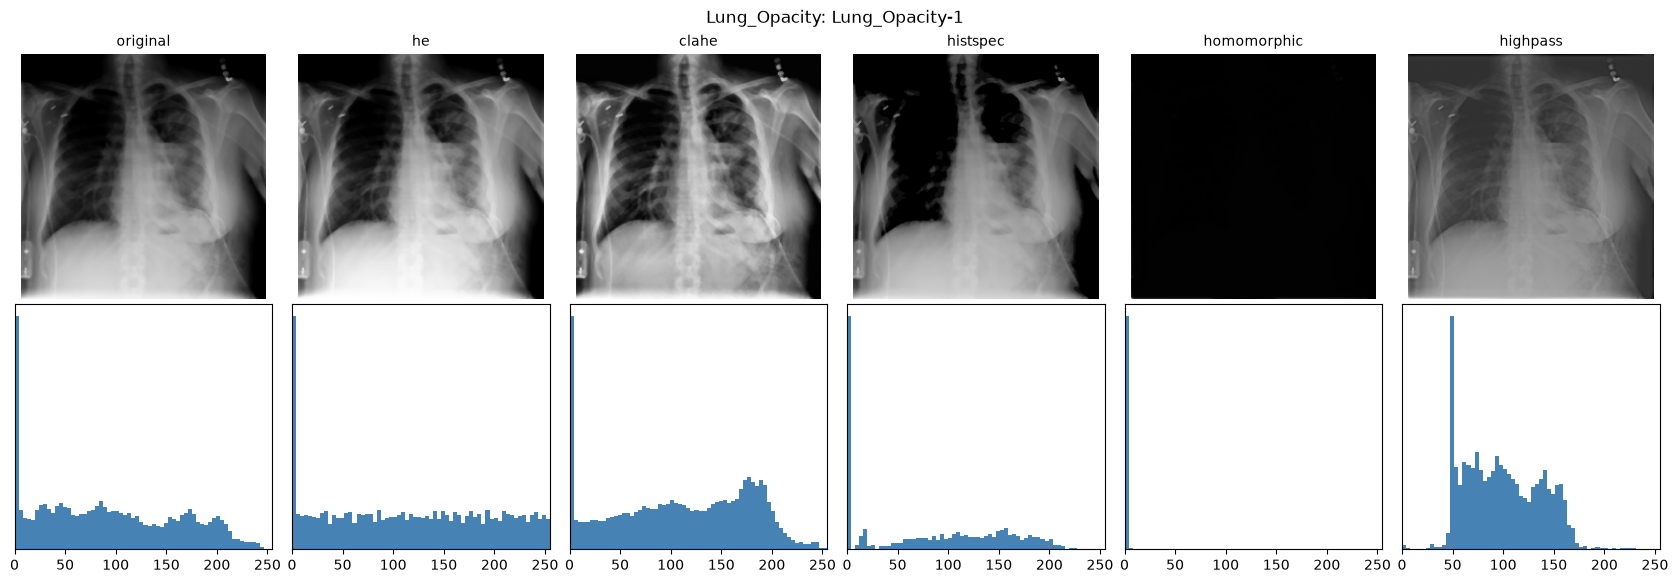

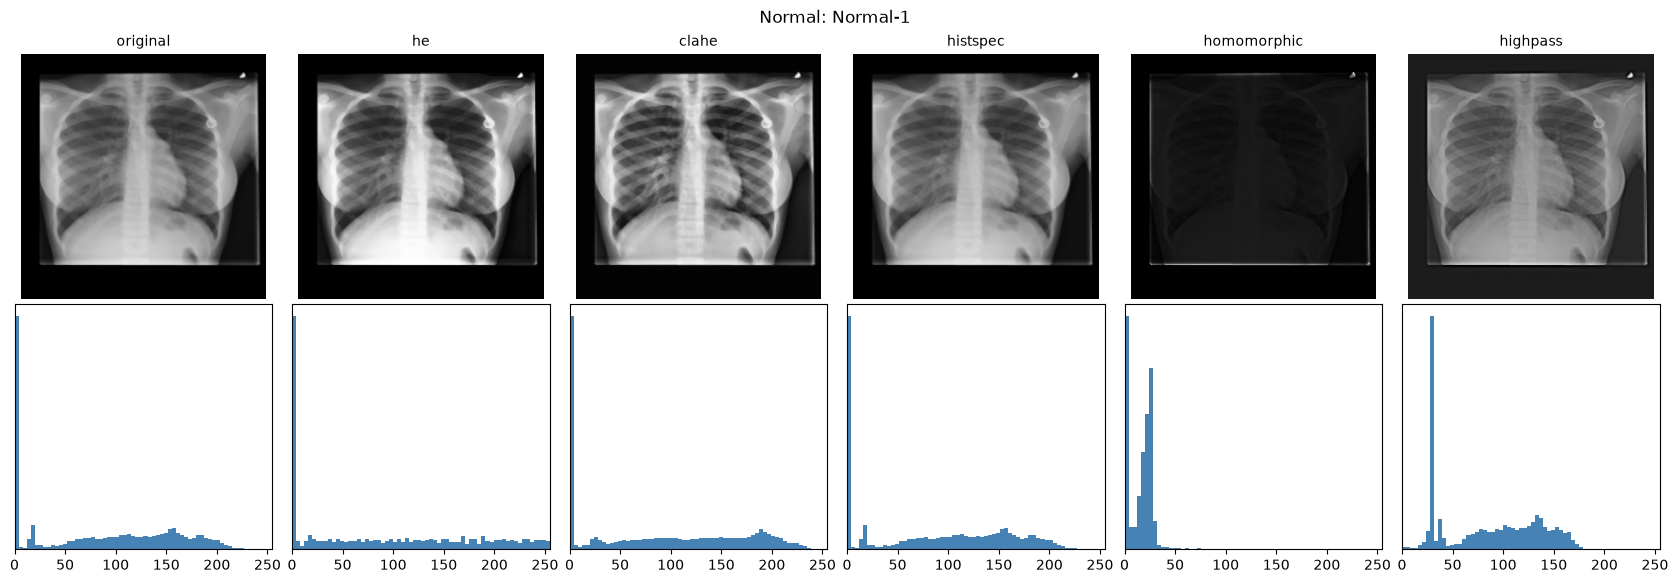

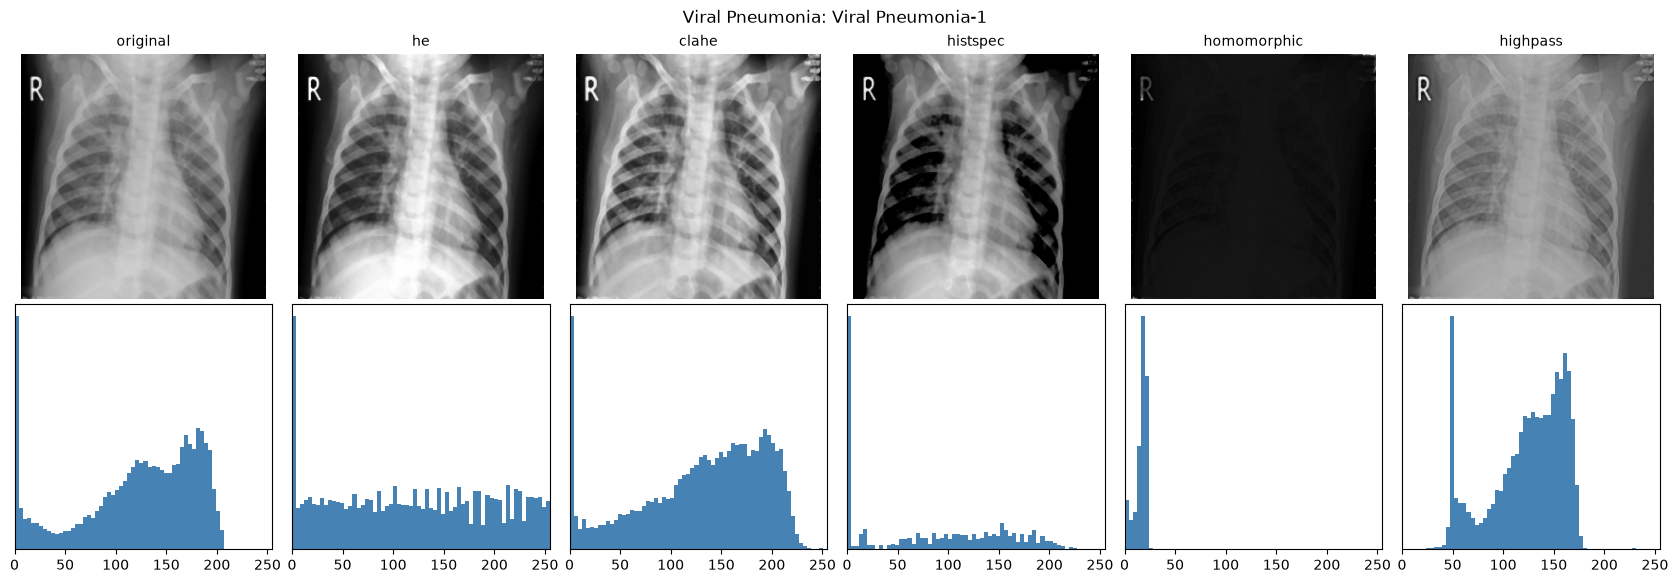

In [16]:
ref = load_pre(train[train.label == 0].iloc[0], cfg)      # reference for histogram specification
shown = [m for m in METHODS if m != "none"]
for cls, g in train.groupby("class_name"):
    r = g.iloc[0]
    img = load_pre(r, cfg)
    variants = {m: enhance(img, m, cfg["enhancement"], ref) for m in shown}
    before_after_grid(img, variants, title=f"{cls}: {r.image_id}", path=FIG / f"before_after_{cls.replace(' ','_')}.png")
    plt.show()

### Fine detail (zoomed crop)
Check whether lung texture/vessels are enhanced or whether noise is amplified.

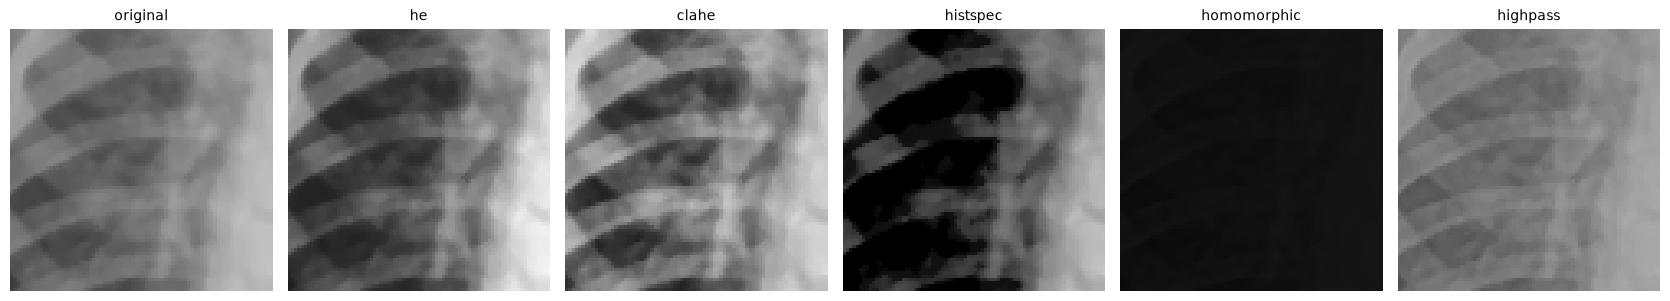

In [17]:
r = train[train.label == 1].iloc[0]
img = load_pre(r, cfg)
imgs = {"original": img, **{m: enhance(img, m, cfg["enhancement"], ref) for m in shown}}
zoom_crops(imgs, (90, 170, 40, 120), path=FIG / "zoom_crops.png"); plt.show()

## 3. What each filter does in the frequency domain (Unit III)

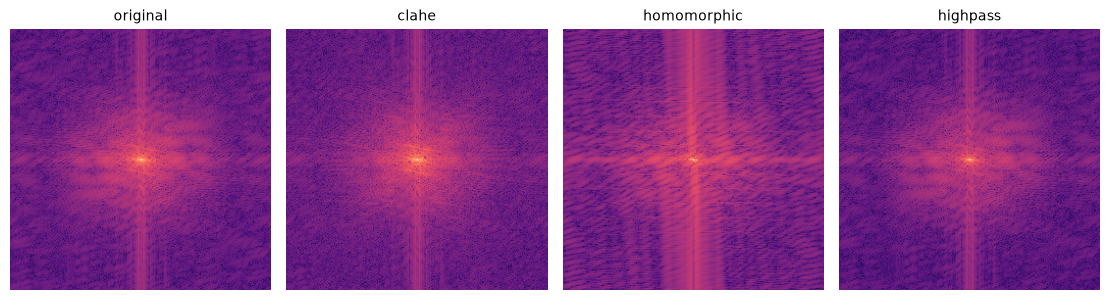

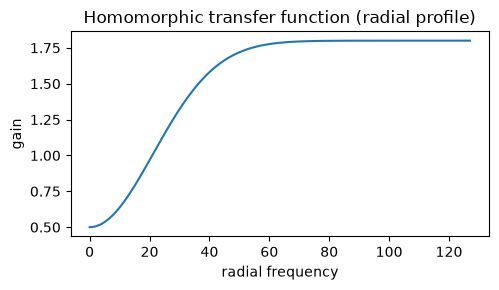

In [18]:
variants = {m: enhance(img, m, cfg["enhancement"], ref) for m in ["clahe", "homomorphic", "highpass"]}
spectra_grid(img, variants, path=FIG / "spectra.png"); plt.show()

H = homomorphic_H((256, 256), **cfg["enhancement"]["homomorphic"])
plt.figure(figsize=(5, 3)); plt.plot(H[128, 128:]); plt.xlabel("radial frequency"); plt.ylabel("gain")
plt.title("Homomorphic transfer function (radial profile)"); plt.tight_layout(); plt.savefig(FIG / "homomorphic_H.png", dpi=150)

## 4. Quantitative comparison
No-reference measures (entropy, contrast, sharpness) plus **lung/background separability** computed with the ground-truth masks — this is the metric most relevant to the next stage (segmentation).

In [19]:
res = compare_enhancements(train, cfg, METHODS, n_per_class=30)
res.to_csv(ROOT / cfg["paths"]["reports"] / "enhancement_metrics.csv", index=False)
summary = res.groupby("method")[["entropy", "contrast", "sharpness", "separability"]].mean().round(3).loc[METHODS]
summary.to_csv(ROOT / cfg["paths"]["reports"] / "enhancement_summary.csv")
summary

enhancement metrics: 100%|██████████| 90/90 [00:03<00:00, 26.59it/s]


,entropy,contrast,sharpness,separability
method,,,,
none,7.328,59.295,30.739,0.581
he,7.173,76.063,43.255,0.803
clahe,7.488,61.628,52.791,0.691
histspec,5.668,70.423,39.438,0.945
homomorphic,4.310,9.957,9.364,0.351
highpass,7.054,44.802,30.045,0.573


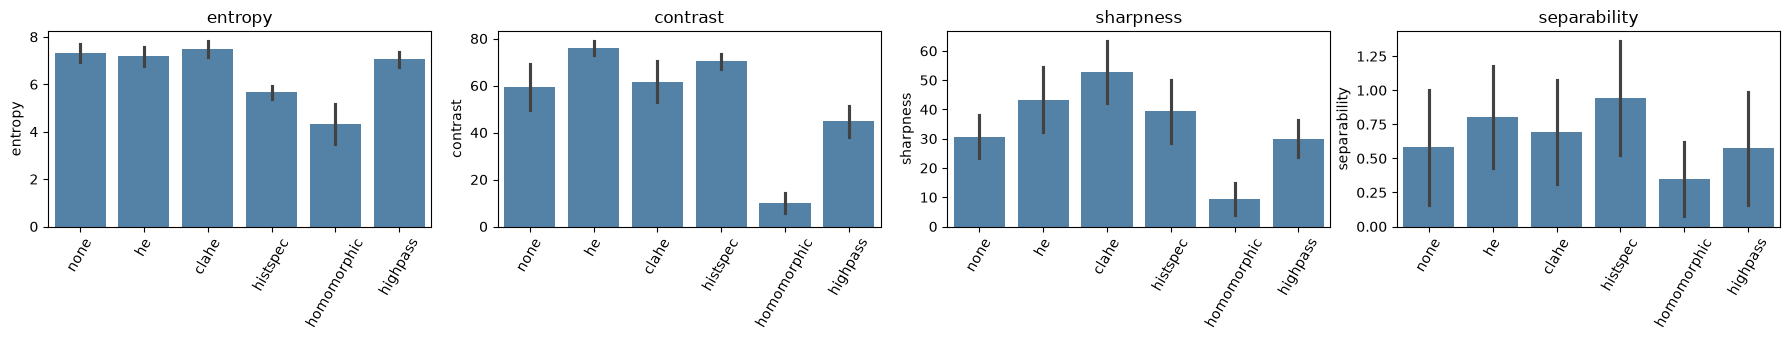

In [20]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for a, col in zip(ax, ["entropy", "contrast", "sharpness", "separability"]):
    sns.barplot(data=res, x="method", y=col, order=METHODS, ax=a, errorbar="sd", color="steelblue")
    a.set_title(col); a.tick_params(axis="x", rotation=60); a.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "enhancement_metrics.png", dpi=150)

**Caution when reading this table:** higher entropy/contrast/sharpness is *not automatically better* — noise amplification also raises sharpness. Separability and, later, downstream classification accuracy are the real tests (see the ablation table in Part 6).

## 5. Parameter sensitivity (CLAHE clip limit, homomorphic cutoff)

In [21]:
from src.evaluation.metrics import region_separability
rows = sample_rows(train, 15).itertuples()
rows = [r for r in rows if r.mask_path]
out = []
for r in rows:
    im, mk = load_pre(r, cfg), load_mask(r.mask_path, cfg["image_size"])
    for clip in [1, 2, 3, 4, 6]:
        e = enhance(im, "clahe", {"clahe": {"clip_limit": clip, "tile_grid": 8}})
        out.append(dict(method="clahe", param=clip, sep=region_separability(e, mk), sharp=quality_report(e)["sharpness"]))
    for d0 in [10, 20, 30, 50, 80]:
        e = enhance(im, "homomorphic", {"homomorphic": {**cfg["enhancement"]["homomorphic"], "d0": d0}})
        out.append(dict(method="homomorphic", param=d0, sep=region_separability(e, mk), sharp=quality_report(e)["sharpness"]))
sens = pd.DataFrame(out).groupby(["method", "param"]).mean().round(3); sens

sep   sharp
method      param               
clahe       1      0.628  43.807
            2      0.650  54.061
            3      0.646  62.179
            4      0.624  68.356
            6      0.602  76.585
homomorphic 10     0.339   9.398
            20     0.313   9.484
            30     0.324   9.577
            50     0.352  10.426
            80     0.378  12.954

## 6. Decision
Fill in after running on the real dataset:

| Choice | Value | Evidence |
|---|---|---|
| Denoiser | median, 3×3 | Estimated real noise sigma = [from section 1]. Median was within ~0.5 dB of the best on Gaussian, Poisson and speckle noise and far better on salt-and-pepper (42.1 dB). NLM with default settings was ineffective. |
| Enhancement shortlist | histspec, HE, CLAHE (spatial); high-pass (frequency) | Separability 0.945 / 0.803 / 0.691 vs 0.581 baseline. High-pass 0.579 (no gain). |
| Candidate for segmentation | histogram specification (provisional) | Highest separability (0.945). Check visually and confirm the reference image is representative. |
| Candidate for classification features | CLAHE |Highest sharpness (52.8) and entropy (7.49 vs 5.67 for histspec). |
| Frequency-domain finding | Homomorphic not recommended for segmentation | Lowest separability (0.303): it removes the large-scale lung/background brightness difference by design. |
| Parameters | CLAHE clip_limit = 2, tile 8×8; homomorphic gl = 0.7, gh = 1.5, d0 = 10 | Values in config.yaml. |

Final selection between enhancement methods is deferred to the ablation study, because separability measures intensity contrast, not downstream accuracy. Frequency-domain filters needed outlier clipping because bright text markers dominated the intensity range.